# StrokeSense - Part 1: forensic audit and model evidence
**Question.** Once age is accounted for, how much does machine learning add to stroke prediction on this dataset?

Every modelling decision here uses the 80% development split. The 20% test split is not evaluated in this notebook.

In [1]:
import sys, warnings; sys.path.insert(0, ".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
BLUE, ORANGE, INK, MUTE = "#2a78d6", "#eb6834", "#222", "#898781"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
  "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlelocation": "left"})
df = pd.read_csv("../data/raw/stroke_data.csv"); df.head()

(row preview removed: raw records are not redistributed)


## 1. Structure and integrity

In [2]:
pd.Series({"rows": len(df), "columns": df.shape[1], "duplicate ids": df.id.duplicated().sum(),
 "duplicate rows ignoring id": df.drop(columns="id").duplicated().sum(), "missing bmi": df.bmi.isna().sum(),
 "stroke cases": df.stroke.sum(), "stroke %": round(100*df.stroke.mean(), 2),
 "label changes down the file": int((df.stroke.diff().fillna(0) != 0).sum()),
 "Unknown smoking": (df.smoking_status=="Unknown").sum(), "Unknown smoking under 18": ((df.smoking_status=="Unknown")&(df.age<18)).sum()})

rows                           5110.00
columns                          12.00
duplicate ids                     0.00
duplicate rows ignoring id        0.00
missing bmi                     201.00
stroke cases                    249.00
stroke %                          4.87
label changes down the file       1.00
Unknown smoking                1544.00
Unknown smoking under 18        682.00
dtype: float64

The file is sorted by the target, so any unshuffled split would be invalid. 682 of the 1,544 `Unknown` smokers are under 18: a structural unknown, not a missing answer. We shuffle, stratify, and delete no rows.

In [3]:
from src.experiments import load_split
X, _, y, _ = load_split()      # second and fourth objects are the locked test split
D = X.assign(stroke=y); print(D.shape, int(D.stroke.sum()), "stroke cases in development data")

(4088, 11) 199 stroke cases in development data


## 2. Exploration (development data)

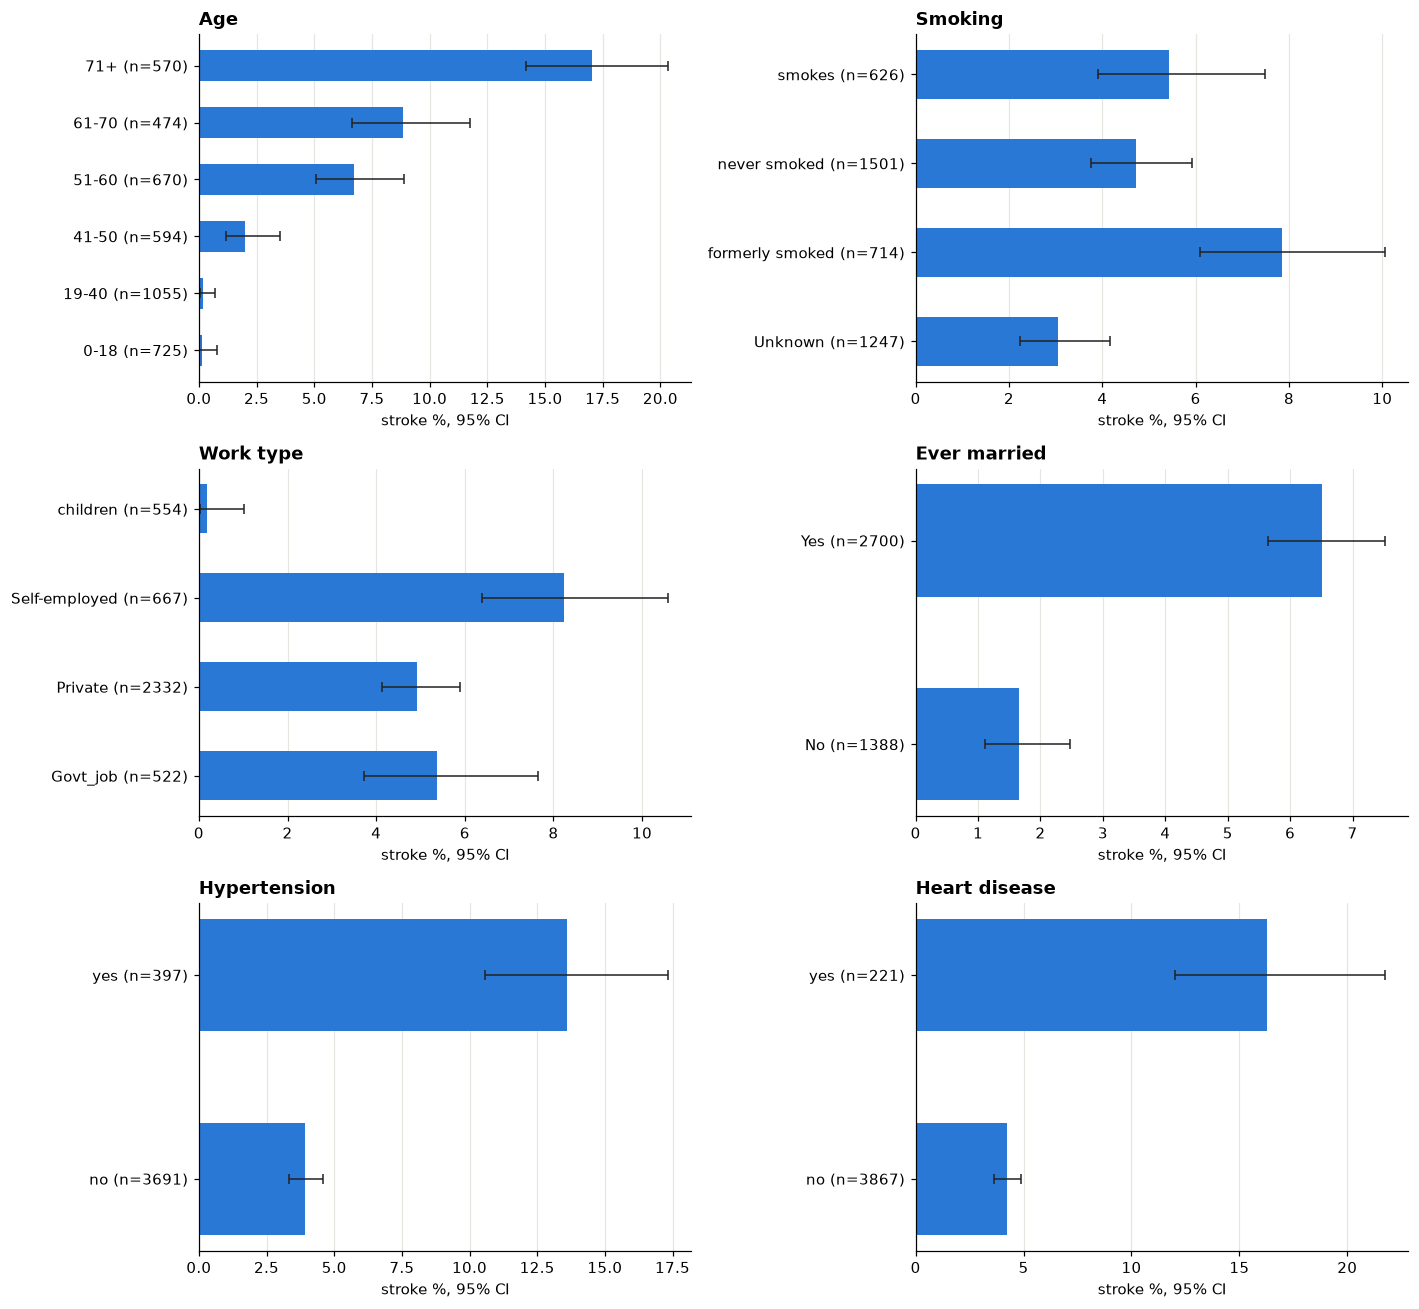

In [4]:
def wilson(k, n): 
    ci = stats.binomtest(int(k), int(n)).proportion_ci(method="wilson"); return ci.low, ci.high
def rate_plot(ax, g, title):
    t = D.groupby(g, observed=True).stroke.agg(["sum", "size"]); t = t[t["size"] >= 15]
    r = t["sum"]/t["size"]; ci = np.array([wilson(a, b) for a, b in t.values])
    ax.barh(range(len(t)), 100*r, color=BLUE, height=.55)
    ax.errorbar(100*r, range(len(t)), xerr=[100*(r-ci[:,0]).clip(lower=0), 100*(ci[:,1]-r).clip(lower=0)], fmt="none", ecolor=INK, capsize=3, lw=1)
    ax.set_yticks(range(len(t))); ax.set_yticklabels([f"{i} (n={n})" for i, n in zip(t.index, t["size"])]); ax.set_title(title); ax.set_xlabel("stroke %, 95% CI"); ax.grid(axis="y", visible=False)
fig, ax = plt.subplots(3, 2, figsize=(13, 12)); ax = ax.ravel()
rate_plot(ax[0], pd.cut(D.age, [-1,18,40,50,60,70,83], labels=["0-18","19-40","41-50","51-60","61-70","71+"]), "Age")
rate_plot(ax[1], D.smoking_status, "Smoking"); rate_plot(ax[2], D.work_type, "Work type"); rate_plot(ax[3], D.ever_married, "Ever married")
rate_plot(ax[4], D.hypertension.map({0:"no",1:"yes"}), "Hypertension"); rate_plot(ax[5], D.heart_disease.map({0:"no",1:"yes"}), "Heart disease")
plt.tight_layout(); plt.savefig("../reports/figures/rates.png"); plt.show()

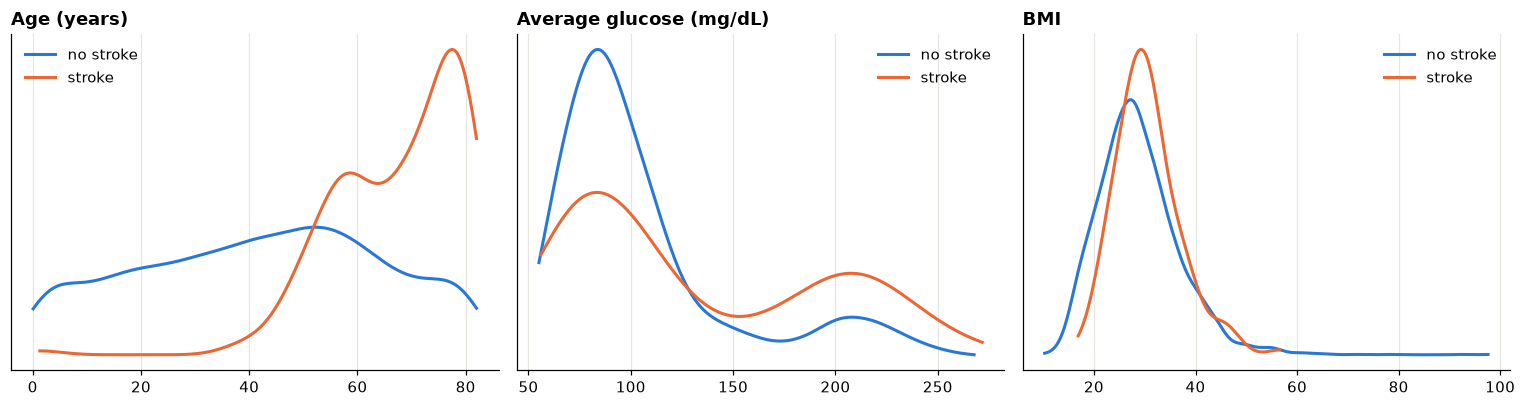

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c, t in zip(ax, ["age","avg_glucose_level","bmi"], ["Age (years)","Average glucose (mg/dL)","BMI"]):
    for v, col, l in [(0, BLUE, "no stroke"), (1, ORANGE, "stroke")]:
        s = D.loc[D.stroke==v, c].dropna(); g = np.linspace(s.min(), s.max(), 200); a.plot(g, stats.gaussian_kde(s)(g), color=col, lw=2, label=l)
    a.set_title(t); a.set_yticks([]); a.legend(frameon=False)
plt.tight_layout(); plt.savefig("../reports/figures/distributions.png"); plt.show()

**Glucose has two humps.** High readings form a second subpopulation around 200 mg/dL. They look like a plausible group rather than errors, so trimming them as outliers would delete patients with a higher stroke rate.

### Confounding: marriage does not cause strokes
Raw odds ratios against odds ratios adjusted for a smooth age effect.

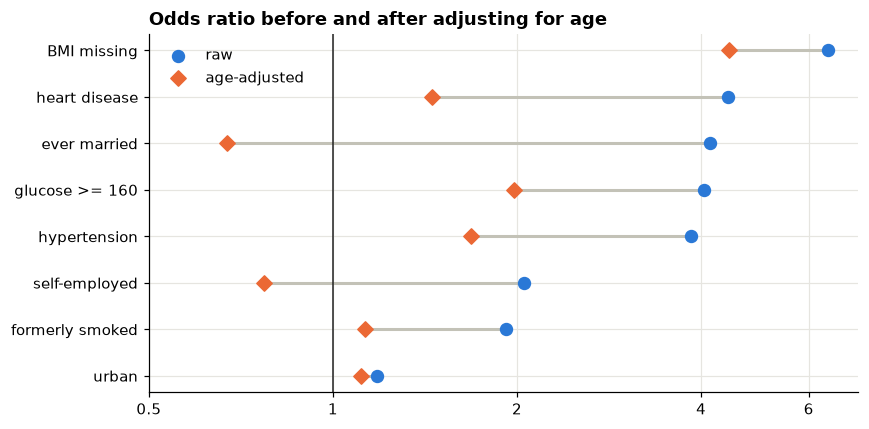

,raw OR,age-adjusted OR
factor,,
ever married,4.14,0.67
self-employed,2.05,0.77
hypertension,3.85,1.68
heart disease,4.43,1.45
glucose >= 160,4.05,1.98
formerly smoked,1.92,1.13
urban,1.18,1.11
BMI missing,6.45,4.44


In [6]:
rows = []
A = np.column_stack([(D.age-45)/20, ((D.age-45)/20)**2, np.maximum(D.age-60,0)/20])
for n, v in {"ever married": D.ever_married=="Yes", "self-employed": D.work_type=="Self-employed", "hypertension": D.hypertension==1, "heart disease": D.heart_disease==1,
             "glucose >= 160": D.avg_glucose_level>=160, "formerly smoked": D.smoking_status=="formerly smoked", "urban": D.Residence_type=="Urban", "BMI missing": D.bmi.isna()}.items():
    v = v.astype(float).values[:, None]; f = lambda Z: np.exp(LogisticRegression(C=1e6, max_iter=5000).fit(Z, D.stroke).coef_[0][0])
    rows.append((n, f(v), f(np.hstack([v, A]))))
o = pd.DataFrame(rows, columns=["factor","raw OR","age-adjusted OR"]).set_index("factor").round(2)
o2 = o.sort_values("raw OR"); fig, a = plt.subplots(figsize=(8, 4))
a.hlines(range(len(o2)), o2["age-adjusted OR"], o2["raw OR"], color="#c3c2b7", lw=2)
a.scatter(o2["raw OR"], range(len(o2)), color=BLUE, s=60, label="raw", zorder=3); a.scatter(o2["age-adjusted OR"], range(len(o2)), color=ORANGE, marker="D", s=50, label="age-adjusted", zorder=3)
a.set_yticks(range(len(o2))); a.set_yticklabels(o2.index); a.axvline(1, color=INK, lw=1); a.set_xscale("log"); a.set_xticks([.5,1,2,4,6]); a.set_xticklabels([.5,1,2,4,6]); a.minorticks_off(); a.set_title("Odds ratio before and after adjusting for age"); a.legend(frameon=False); plt.tight_layout(); plt.savefig("../reports/figures/confounding.png"); plt.show(); o

## 3. The BMI trap
Is a *blank* BMI a stronger signal than BMI itself? A value that is blank more often for stroke patients, even at the same age, suggests recording happened after or because of the outcome.

In [7]:
b = pd.cut(D.age, [40, 60, 70, 83]); t = D.groupby([b, D.bmi.isna()], observed=True).stroke.agg(["size","sum","mean"]).round(3); print(t)
ab = pd.read_csv("../artifacts/results/ablation_cv.csv"); ab.groupby("label", sort=False)[["pr_auc","roc_auc","age_matched_auc","brier"]].mean().round(4)

                size  sum   mean
age      bmi                    
(40, 60] False  1218   50  0.041
         True     46    7  0.152
(60, 70] False   450   35  0.078
         True     24    7  0.292
(70, 83] False   517   75  0.145
         True     53   22  0.415


,pr_auc,roc_auc,age_matched_auc,brier
label,,,,
A raw + median BMI | Logistic,0.1857,0.8381,0.5728,0.0429
B peer BMI imputation | Logistic,0.1860,0.8381,0.5725,0.0429
C + BMI-missing flag | Logistic,0.2251,0.8510,0.6310,0.0421
D + peer-relative features | Logistic,0.1861,0.8378,0.5702,0.0429
E + smoking split | Logistic,0.1859,0.8381,0.5732,0.0429
F + burden count | Logistic,0.1843,0.8377,0.5728,0.0429
G all except flag | Logistic,0.1849,0.8373,0.5691,0.0429
A raw + median BMI | EBM monotone,0.1842,0.8397,0.5973,0.0433
B peer BMI imputation | EBM monotone,0.1800,0.8344,0.5783,0.0434


The flag is the only added feature that clearly raises scores, and it is the one we refuse. Nothing tells us *why* BMI is blank; if it reflects incomplete notes for stroke patients, the flag will not exist at prediction time. We report it as a sensitivity analysis and keep it out of the final model. The cost is real and visible in the table.

The other engineered ideas (peer-relative deviation, age-conditional imputation, smoking split, burden count) did not help. They stay documented as negative results and out of the model.

## 4. Benchmark: 4 x 5-fold cross-validation, development data only

In [8]:
m = pd.concat([pd.read_csv("../artifacts/results/models_cv.csv"), pd.read_csv("../artifacts/results/shape_cv.csv")])
cols = ["pr_auc","roc_auc","age_matched_auc","brier","mean_pred","recall_top20","net_benefit_10"]
T = m.groupby("label")[cols].mean().round(4); T.insert(1, "pr_auc_sd", m.groupby("label").pr_auc.std().round(3)); T.sort_values("pr_auc", ascending=False)

,pr_auc,pr_auc_sd,roc_auc,age_matched_auc,brier,mean_pred,recall_top20,net_benefit_10
label,,,,,,,,
HGB mono pairs,0.2140,0.034,0.8468,0.6114,0.0423,0.0491,0.6645,0.0138
HGB mono,0.2114,0.039,0.8427,0.5957,0.0425,0.0491,0.6632,0.0129
HistGradientBoosting,0.2100,0.039,0.8435,0.5993,0.0424,0.0486,0.6645,0.0135
HGB,0.2093,0.036,0.8420,0.5946,0.0426,0.0486,0.6657,0.0125
XGBoost,0.2073,0.043,0.8436,0.5994,0.0426,0.0483,0.6633,0.0136
HGB mono pairs small,0.2071,0.036,0.8473,0.6097,0.0423,0.0489,0.6745,0.0141
HGB small,0.2035,0.035,0.8455,0.6031,0.0423,0.0487,0.6720,0.0137
HGB mono additive,0.1972,0.035,0.8478,0.6210,0.0423,0.0489,0.6733,0.0134
CatBoost,0.1878,0.035,0.8428,0.5956,0.0429,0.0479,0.6759,0.0134


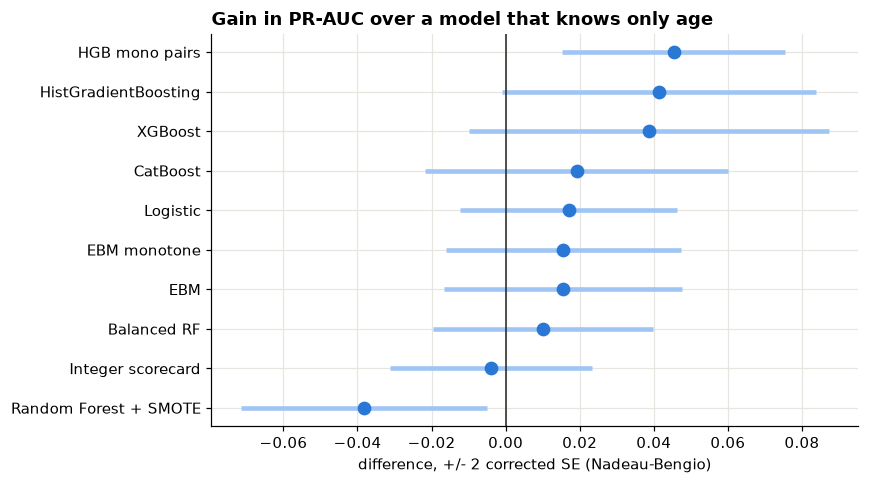

In [9]:
P = m.pivot(index="fold", columns="label", values="pr_auc"); keep = ["HGB mono pairs","HistGradientBoosting","XGBoost","CatBoost","Logistic","EBM","EBM monotone","Balanced RF","Integer scorecard","Random Forest + SMOTE"]
d = P[keep].sub(P["Age only (logistic)"], axis=0); mu = d.mean(); ci = 2*d.std()*np.sqrt(1/20+.25); s = mu.sort_values().index
fig, a = plt.subplots(figsize=(8, 4.5)); a.errorbar(mu[s], range(len(s)), xerr=ci[s], fmt="o", color=BLUE, ecolor="#9ec5f4", elinewidth=3, ms=8); a.axvline(0, color=INK, lw=1)
a.set_yticks(range(len(s))); a.set_yticklabels(s); a.set_title("Gain in PR-AUC over a model that knows only age"); a.set_xlabel("difference, +/- 2 corrected SE (Nadeau-Bengio)"); plt.tight_layout(); plt.savefig("../reports/figures/gain_over_age.png"); plt.show()

At this point boosting looks like a clear winner. Section 5 shows why that reading is wrong.

## 5. The missing-data artifact: constant imputation
All blank BMIs were filled with the *same* number (the median). Trees can isolate that exact value and so rebuild the missing-BMI flag we refused. Test: refit with (a) an age-conditional random draw instead of a constant, and (b) no BMI at all.

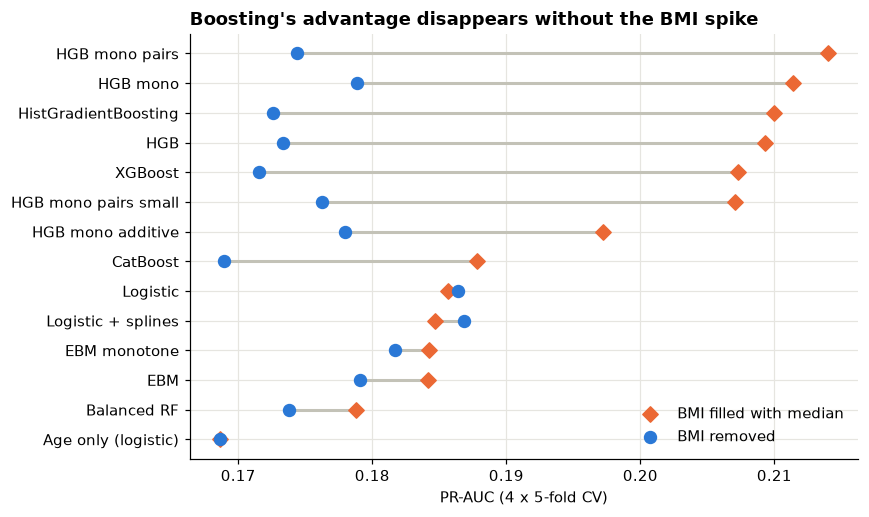

mode,median,draw,drop
label,,,
Age only (logistic),0.1686,0.1686,0.1686
Balanced RF,0.1788,0.1675,0.1738
EBM,0.1841,0.1755,0.1791
EBM monotone,0.1842,0.1769,0.1817
Logistic + splines,0.1847,0.1846,0.1869
Logistic,0.1857,0.1843,0.1864
CatBoost,0.1878,0.1645,0.1689
HGB mono additive,0.1972,0.1749,0.1780
HGB mono pairs small,0.2071,0.1671,0.1763


In [10]:
L = pd.read_csv("../artifacts/results/leak_cv.csv")
Q = L.pivot_table(index="label", columns="mode", values="pr_auc")[["median","draw","drop"]].sort_values("median"); 
fig, a = plt.subplots(figsize=(8, 4.8)); n = range(len(Q))
a.hlines(n, Q["drop"], Q["median"], color="#c3c2b7", lw=2)
a.scatter(Q["median"], n, color=ORANGE, marker="D", s=50, label="BMI filled with median", zorder=3); a.scatter(Q["drop"], n, color=BLUE, s=60, label="BMI removed", zorder=3)
a.set_yticks(n); a.set_yticklabels(Q.index); a.set_xlabel("PR-AUC (4 x 5-fold CV)"); a.set_title("Boosting's advantage disappears without the BMI spike"); a.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.savefig("../reports/figures/leak.png"); plt.show(); Q.round(4)

In [11]:
P = L[L["mode"]=="drop"].pivot(index="fold", columns="label", values="pr_auc"); d = P.sub(P["Age only (logistic)"], axis=0).drop(columns="Age only (logistic)")
pd.DataFrame({"gain over age-only": d.mean(), "+/- 2 corrected SE": 2*d.std()*np.sqrt(1/20+.25), "folds won /20": (d>0).sum()}).round(4)

,gain over age-only,+/- 2 corrected SE,folds won /20
label,,,
Balanced RF,0.0052,0.0310,13
CatBoost,0.0003,0.0293,10
EBM,0.0104,0.0360,11
EBM monotone,0.0131,0.0316,13
HGB,0.0047,0.0393,12
HGB mono,0.0102,0.0309,12
HGB mono additive,0.0093,0.0204,14
HGB mono pairs,0.0057,0.0243,11
HGB mono pairs small,0.0076,0.0238,13


### Reading section 5
The apparent advantage of boosting under median-imputed BMI shrinks strongly when BMI is excluded or imputed by random draw. This suggests the models exploited the missingness pattern rather than measured BMI. It does **not** prove target leakage: blank BMI may be a recording artifact, a proxy for something unmeasured, or real information. We exclude it because we cannot know that it would exist at prediction time. SMOTE and balanced forests also inflate predicted risk (mean about 32% against a true 4.9%).

## 6. Final selection
**Rule, written in `src/day1.py` before the run:** among BMI-free models take the highest mean PR-AUC, then the simplest model within one corrected standard error. Every model uses the same 4 x stratified 5-fold split (20 held-out folds).

**Age-matched AUC:** share of case/control pairs within +/-3 years of age ranked correctly (ties count half), using pairs scored by the same outer-fold model. Section 8 gives sensitivity and uncertainty. The bootstrap table below pools scores across folds and is superseded by section 8 for age-matched AUC.

In [12]:
pd.read_csv("../artifacts/results/final_benchmark.csv", index_col=0).round(4)

,pr_auc,roc_auc,age_matched_auc,brier,net_benefit_10,pr_sd,vs_best,se,within_1se,vs_age_spline,2se_age
label,,,,,,,,,,,
Logistic (4 clinical),0.1899,0.8423,0.5895,0.0427,0.0133,0.0389,0.0000,0.0000,True,0.0183,0.0235
Logistic + splines,0.1869,0.8367,0.5705,0.0430,0.0115,0.0388,-0.0030,0.0124,True,0.0153,0.0270
Logistic,0.1864,0.8386,0.5745,0.0429,0.0126,0.0370,-0.0035,0.0065,True,0.0148,0.0268
Logistic (9 features),0.1864,0.8386,0.5745,0.0429,0.0126,0.0370,-0.0035,0.0065,True,0.0148,0.0268
EBM monotone,0.1817,0.8342,0.5736,0.0433,0.0118,0.0390,-0.0082,0.0063,False,0.0101,0.0270
EBM,0.1791,0.8334,0.5607,0.0432,0.0117,0.0393,-0.0108,0.0102,False,0.0075,0.0286
HGB mono,0.1789,0.8389,0.5754,0.0431,0.0128,0.0318,-0.0110,0.0176,True,0.0073,0.0321
HGB mono additive,0.1780,0.8395,0.5771,0.0428,0.0117,0.0291,-0.0119,0.0112,False,0.0064,0.0225
HGB mono pairs small,0.1763,0.8392,0.5729,0.0428,0.0128,0.0282,-0.0136,0.0120,False,0.0047,0.0224


In [13]:
display(pd.read_csv("../artifacts/results/bootstrap_ci.csv", header=[0,1], index_col=0)); display(pd.read_csv("../artifacts/results/persistence.csv").round(4)); display(pd.read_csv("../artifacts/results/calibration.csv", index_col=0).round(3))

pr                  roc                   am         \
                       0.025    0.5  0.975  0.025    0.5  0.975  0.025    0.5   
m                                                                               
Age spline only        0.133  0.154  0.181  0.811  0.833  0.852  0.467  0.489   
Logistic (4 clinical)  0.144  0.175  0.206  0.817  0.843  0.863  0.541  0.583   
Logistic (9 features)  0.140  0.171  0.202  0.813  0.839  0.860  0.524  0.571   
Scorecard (BMI-free)   0.138  0.167  0.196  0.809  0.835  0.856  0.496  0.545   

                              
                       0.975  
m                             
Age spline only        0.513  
Logistic (4 clinical)  0.626  
Logistic (9 features)  0.610  
Scorecard (BMI-free)   0.593

,seed,label,median,drop
0,7,Logistic,0.1744,0.1769
1,7,HGB mono pairs,0.1984,0.1743
2,7,XGBoost,0.1991,0.1715
3,101,Logistic,0.1843,0.1879
4,101,HGB mono pairs,0.2145,0.1863
5,101,XGBoost,0.2043,0.1755
6,2024,Logistic,0.1844,0.1838
7,2024,HGB mono pairs,0.2123,0.1762
8,2024,XGBoost,0.2074,0.1680


,slope,intercept,ece,mean_pred,q50,q95,q99
Age spline only,1.152,0.347,0.006,0.049,0.020,0.168,0.174
Logistic (9 features),1.071,0.161,0.012,0.049,0.023,0.183,0.288
Logistic (4 clinical),1.099,0.227,0.010,0.049,0.023,0.182,0.280
Scorecard (BMI-free),0.946,-0.123,0.008,0.049,0.012,0.184,0.279
HGB mono pairs | drop,0.915,-0.198,0.009,0.049,0.013,0.204,0.264
HGB mono pairs | median,0.932,-0.154,0.006,0.049,0.012,0.203,0.330
Logistic | median,1.068,0.154,0.012,0.049,0.023,0.184,0.288
Logistic | median+flag,1.057,0.124,0.007,0.049,0.022,0.183,0.348
HGB mono pairs | median+flag,0.937,-0.143,0.006,0.049,0.013,0.203,0.353
XGBoost | median+flag,0.930,-0.142,0.006,0.048,0.011,0.200,0.356


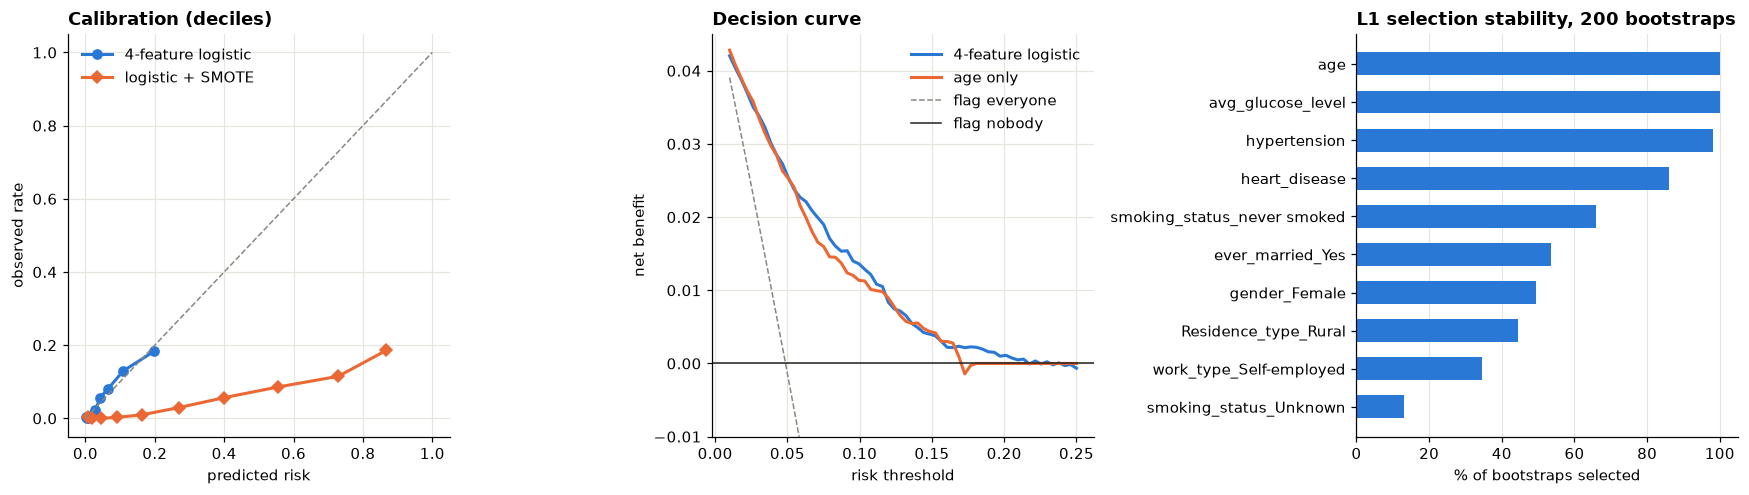

In [14]:
Z = np.load("../artifacts/results/oof.npz"); yy = Z["y"]; fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
p4, pa, ps = Z["Logistic (4 clinical)"], Z["Age spline only"], Z["Logistic + SMOTE ~ drop"]
for p, c, mk, l in [(p4, BLUE, "o", "4-feature logistic"), (ps, ORANGE, "D", "logistic + SMOTE")]:
    g = pd.DataFrame(dict(y=yy, p=p)).groupby(pd.qcut(p, 10, duplicates="drop"), observed=True).mean(); ax[0].plot(g.p, g.y, marker=mk, color=c, lw=2, label=l)
ax[0].plot([0, 1], [0, 1], color=MUTE, lw=1, ls="--"); ax[0].set_title("Calibration (deciles)"); ax[0].set_xlabel("predicted risk"); ax[0].set_ylabel("observed rate"); ax[0].legend(frameon=False)
t = np.linspace(.01, .25, 60); nb = lambda p: [((p>=k)&(yy==1)).mean()-((p>=k)&(yy==0)).mean()*k/(1-k) for k in t]
ax[1].plot(t, nb(p4), color=BLUE, lw=2, label="4-feature logistic"); ax[1].plot(t, nb(pa), color=ORANGE, lw=2, label="age only"); ax[1].plot(t, nb(np.ones(len(yy))), color=MUTE, lw=1, ls="--", label="flag everyone"); ax[1].axhline(0, color=INK, lw=1, label="flag nobody")
ax[1].set_ylim(-.01, .045); ax[1].set_title("Decision curve"); ax[1].set_xlabel("risk threshold"); ax[1].set_ylabel("net benefit"); ax[1].legend(frameon=False)
st = pd.read_csv("../artifacts/results/stability.csv").head(10)[::-1]; ax[2].barh(st.feature, 100*st.selected, color=BLUE, height=.6); ax[2].set_title("L1 selection stability, 200 bootstraps"); ax[2].set_xlabel("% of bootstraps selected"); ax[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("../reports/figures/reliability.png"); plt.show()

In [15]:
import json; display(json.load(open("../models/metadata.json"))); json.load(open("../models/scorecard.json"))

{'model': 'L2 logistic regression, C=0.1, no BMI',
 'features': ['age', 'avg_glucose_level', 'hypertension', 'heart_disease'],
 'threshold': 0.05175,
 'threshold_rule': 'highest out-of-fold threshold with sensitivity >= 0.8',
 'n_dev': 4088,
 'n_dev_strokes': 199,
 'oof_at_threshold_optimistic': {'sensitivity': 0.8040201005025126,
  'specificity': 0.7274363589611725,
  'precision': 0.13114754098360656,
  'flagged_fraction': 0.2984344422700587},
 'nested_estimate': {'sensitivity': 0.793,
  'specificity': 0.732,
  'precision': 0.131,
  'source': 'artifacts/results/operating_point_nested.csv'},
 'standardised_coefficients': {'age': 1.3573759012631923,
  'avg_glucose_level': 0.18272874604208403,
  'hypertension': 0.14333593755293467,
  'heart_disease': 0.07429288354015978},
 'test_split_scored': False,
 'data_sha256': '644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420',
 'dev_ids_sha256': 'ff84cd1db13b5d010ab8d70a180181cc49ad8d9500aabcbe40dba92b9bc34b71',
 'sklearn': '1.9.1'

{'points': {'age >= 40': 6,
  'age >= 50': 3,
  'age >= 55': 1,
  'age >= 65': 1,
  'age >= 70': 1,
  'age >= 75': 1,
  'glucose >= 160': 2,
  'hypertension': 1},
 'slope': 0.34664836402241717,
 'intercept': -6.2948465293218305}

### Conclusions
- **Selected:** L2 logistic regression on age, average glucose, hypertension and heart disease; no BMI. It had the highest mean PR-AUC in the section 6 benchmark. Once every algorithm is tuned and given the same four features (section 7), CatBoost ties it (0.194 vs 0.191, difference 0.003 +/- 0.018), so logistic is chosen for simplicity, not superiority. Tuning C barely changes PR-AUC, so the default 0.1 was kept.
- **Beyond age?** A modest yes for ranking people of similar age; corrected estimate in section 8. The PR-AUC gain over age is not established.
- **Calibration** is close to ideal (slope 1.10, ECE 0.010), with no resampling or extra calibration step.
- **Scorecard:** convenient, but its PR-AUC is lower (0.165) and outside the selection rule. It is a communication aid, not the model. Its formula gives 'age' most of the weight.
- **Limits.** The four-feature set was defined from clinical reasoning after seeing exploratory odds ratios; stability was computed afterwards on the same development data. Bootstrap intervals resample fixed out-of-fold predictions, so they omit retraining variation. Our first audit summarised all 5,110 rows, including test labels, before the split was isolated; no model has been scored on the test split.

## 7. Adversarial review
**Fairness of the benchmark.** Section 6 used fixed hyperparameters for tree models and gave the four-feature set only to logistic regression. Here every algorithm gets nested tuning (3-fold inner, 10 outer folds) on both feature sets.

In [16]:
display(pd.read_csv("../artifacts/results/nested_tuning.csv").groupby(["F","m"])[["pr","roc","am"]].mean().round(4)); pd.read_csv("../artifacts/results/bmi_mechanism.csv", index_col=0)

pr     roc      am
F m                               
4 CatBoost  0.1939  0.8412  0.5833
  HGB       0.1779  0.8350  0.5584
  Logistic  0.1914  0.8412  0.5857
  XGB       0.1777  0.8367  0.5799
9 CatBoost  0.1742  0.8348  0.5538
  HGB       0.1724  0.8337  0.5563
  Logistic  0.1869  0.8375  0.5671
  XGB       0.1804  0.8335  0.5578

,BMI observed,all,risk of blank,risk of observed
constant 28.137 (unique),0.1378,0.2089,0.1594,0.0437
median,0.1400,0.2100,0.1545,0.0440
median + jitter sd=4,0.1426,0.1609,0.0864,0.0469
no BMI,0.1513,0.1726,0.0870,0.0470


**Mechanism of the BMI artifact (second table, boosting).** Any constant fill gives PR-AUC near 0.21; adding random jitter to the fill removes the gain (0.161, below the 0.173 of no BMI). Among patients with *recorded* BMI, the median-filled model is worse than no BMI (0.140 vs 0.151). The gain therefore comes from identifying blanks, not from BMI values. Why BMI is blank remains unknown.

**Sanity.** Permuted labels give ROC-AUC 0.487 and PR-AUC 0.050 (chance is 0.5 and 0.049). An independent re-implementation reproduced the headline numbers exactly.

**A weakness.** Restricted to age 40 and over, ROC-AUC is 0.734, against 0.719 for age alone. Much of the 0.84 comes from separating young people from old ones.

## 8. Corrections after review (these supersede earlier operating-point and age-matched numbers)
**Protocol.** Fixed settings, outer 4 x stratified 5-fold. Each threshold comes from inner out-of-fold predictions of the outer training part only and is then frozen. Counts are averages over the four repeats (each repeat scores every patient once), hence fractions. `pr_fold` = mean over 20 folds (primary); `pr_pooled` = mean over repeats of pooled PR-AUC; they are never compared with each other. Intervals resample patients with predictions held fixed, so they omit retraining variation.

In [17]:
T = pd.read_csv("../artifacts/results/operating_point_nested.csv"); display(T.round(3)); display(pd.read_csv("../artifacts/results/paired_vs_logistic.csv").round(2)); display(pd.read_csv("../artifacts/results/nested_selection.csv", index_col=0)); display(pd.read_csv("../artifacts/results/calibration_outer.csv").round(3)); pd.read_csv("../artifacts/results/age_matched_sensitivity.csv").round(3)

,model,tp,fp,sens,sens_ci,spec,spec_ci,precision,prec_ci,f1,f1_ci,fp_ci,fp_range,tp_range,thr,pr_fold,pr_fold_sd,pr_pooled,roc_fold
0,Age only,161.50,1112.75,0.812,"[0.756, 0.863]",0.714,"[0.7, 0.729]",0.127,"[0.117, 0.136]",0.219,"[0.203, 0.234]","[1055.744, 1166.5]","(np.int64(1099), np.int64(1122))","(np.int64(159), np.int64(163))",0.057,0.172,0.030,0.157,0.836
1,Logistic 4,157.75,1043.75,0.793,"[0.732, 0.845]",0.732,"[0.718, 0.745]",0.131,"[0.121, 0.141]",0.225,"[0.209, 0.241]","[990.981, 1095.256]","(np.int64(1025), np.int64(1055))","(np.int64(156), np.int64(159))",0.053,0.190,0.039,0.172,0.842
2,Logistic 9,158.00,1045.00,0.794,"[0.74, 0.847]",0.731,"[0.718, 0.744]",0.131,"[0.121, 0.141]",0.225,"[0.209, 0.241]","[994.744, 1096.019]","(np.int64(1033), np.int64(1052))","(np.int64(156), np.int64(162))",0.053,0.186,0.037,0.168,0.839
3,XGBoost,164.00,1126.25,0.824,"[0.774, 0.872]",0.710,"[0.697, 0.724]",0.127,"[0.119, 0.135]",0.220,"[0.206, 0.234]","[1071.494, 1179.013]","(np.int64(1109), np.int64(1151))","(np.int64(162), np.int64(168))",0.049,0.170,0.028,0.156,0.833
4,EBM monotone,161.50,1072.00,0.812,"[0.755, 0.862]",0.724,"[0.711, 0.738]",0.131,"[0.122, 0.14]",0.225,"[0.21, 0.241]","[1017.244, 1123.544]","(np.int64(1052), np.int64(1090))","(np.int64(160), np.int64(163))",0.059,0.188,0.041,0.167,0.839
5,CatBoost,164.25,1143.00,0.825,"[0.773, 0.872]",0.706,"[0.692, 0.72]",0.126,"[0.118, 0.134]",0.218,"[0.204, 0.232]","[1088.981, 1196.775]","(np.int64(1119), np.int64(1196))","(np.int64(163), np.int64(165))",0.050,0.168,0.029,0.150,0.833
6,HGB mono pairs,161.25,1085.50,0.810,"[0.758, 0.861]",0.721,"[0.707, 0.734]",0.129,"[0.12, 0.138]",0.223,"[0.208, 0.238]","[1036.231, 1140.256]","(np.int64(1024), np.int64(1115))","(np.int64(158), np.int64(163))",0.053,0.177,0.028,0.161,0.842
7,Logistic nested-selection,158.25,1068.75,0.795,"[0.737, 0.844]",0.725,"[0.712, 0.738]",0.129,"[0.119, 0.138]",0.222,"[0.205, 0.237]","[1017.244, 1121.25]","(np.int64(1057), np.int64(1081))","(np.int64(158), np.int64(159))",0.053,0.174,0.028,0.160,0.835


,model,d_tp,d_tp_ci,d_fp,d_fp_ci,d_netbenefit_per1000,ci
0,Age only,3.75,[-4.8 12.5],69.00,[43.2 98.8],0.03,[-2.12 2.19]
1,Logistic 9,0.25,[-4. 5.],1.25,[-11.8 15. ],0.05,[-1.06 1.19]
2,XGBoost,6.25,[-1. 13.8],82.50,[ 54. 111.5],0.47,[-1.32 2.41]
3,EBM monotone,3.75,[-1.5 8.8],28.25,[12.5 44.3],0.55,[-0.7 1.79]
4,CatBoost,6.50,[ 1. 12.2],99.25,[ 77. 120.8],0.31,[-1.08 1.75]
5,HGB mono pairs,3.50,[-2.5 9.8],41.75,[19.7 62.5],0.32,[-1.1 1.83]
6,Logistic nested-selection,0.50,[-2.8 4. ],25.00,[12.5 37.5],-0.20,[-1.02 0.67]


,mean_bootstrap_freq,min,outer_folds_selected
age,1.0000,1.00,20
avg_glucose_level,0.8375,0.66,13
hypertension,0.7975,0.51,12
heart_disease,0.6190,0.40,3
gender,0.0580,0.00,0
ever_married,0.0095,0.00,0
work_type,0.0080,0.00,0
Residence_type,0.0225,0.00,0
smoking_status,0.0110,0.00,0


,model,slope,slope_lo,slope_hi,intercept_in_large,int_lo,int_hi,brier,mean_pred
0,Logistic 4,1.095,0.952,1.240,-0.002,-0.036,0.051,0.043,0.049
1,XGBoost,0.871,0.752,0.989,0.001,-0.043,0.055,0.043,0.049
2,EBM monotone,0.874,0.728,1.014,-0.001,-0.044,0.055,0.043,0.049


,window,weighting,pairs,logistic,lo,hi,age_only,gain,gain_lo,gain_hi
0,0,pair,1903.75,0.582,0.531,0.623,0.500,0.082,0.031,0.123
1,0,case,1903.75,0.575,0.522,0.623,0.500,0.075,0.022,0.123
2,1,pair,5621.50,0.581,0.537,0.616,0.515,0.066,0.021,0.107
3,1,case,5621.50,0.575,0.529,0.612,0.511,0.064,0.016,0.105
4,3,pair,12676.50,0.590,0.551,0.629,0.529,0.061,0.015,0.104
5,3,case,12676.50,0.586,0.545,0.625,0.529,0.057,0.017,0.102
6,5,pair,19088.00,0.597,0.559,0.636,0.543,0.054,0.013,0.097
7,5,case,19088.00,0.595,0.554,0.633,0.553,0.041,-0.000,0.084


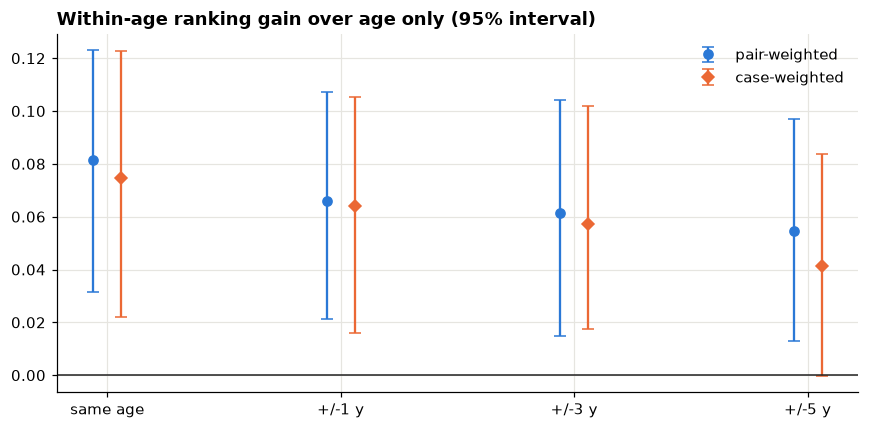

In [18]:
S = pd.read_csv("../artifacts/results/age_matched_sensitivity.csv"); fig, a = plt.subplots(figsize=(8, 4))
for k, (w, c, m) in enumerate([("pair", BLUE, "o"), ("case", ORANGE, "D")]):
    q = S[S.weighting==w]; a.errorbar(np.arange(4)+.12*(k-.5), q.gain, yerr=[q.gain-q.gain_lo, q.gain_hi-q.gain], fmt=m, color=c, capsize=4, label=w+"-weighted")
a.set_xticks(range(4)); a.set_xticklabels(["same age", "+/-1 y", "+/-3 y", "+/-5 y"]); a.axhline(0, color=INK, lw=1); a.legend(frameon=False); a.set_title("Within-age ranking gain over age only (95% interval)"); plt.tight_layout(); plt.savefig("../reports/figures/age_matched.png"); plt.show()

**The 0.061 versus 0.093 discrepancy.** 0.061 compares pairs inside the same fold. 0.093 came from pooled scores averaged over repeats: different fold models put near-identical ages on slightly different scales, which pushed age-only below chance (0.489) and inflated the gap. **0.093 is withdrawn; the estimate is 0.061 (95% interval 0.015 to 0.104).** The gain stays positive at every window; at +/-5 years, case-weighted, the interval touches zero.

**Operating point.** With honest thresholds the logistic model reaches 79.3% sensitivity (not the 80.4% seen when the threshold was chosen on the same data). The earlier 33-alarm XGBoost advantage disappears: XGBoost catches 6 more strokes with 82 more false alarms, and net benefit at 5% does not differ clearly for any model.

**Feature selection.** Repeating a stability selection inside every outer fold gives PR-AUC 0.174, against 0.190 for the four features chosen after exploration, so 0.190 is probably optimistic. All nine BMI-free variables, with no selection step, give 0.186. Age is always selected, glucose and hypertension in 13 and 12 of 20 folds, heart disease in 3. Selection depends on the penalty: section 6 used a weaker one and reported 86% for heart disease. Heart disease is kept on clinical grounds, not on stability.

**Conclusion.** Keep the four-feature logistic model for parsimony, calibration (slope 1.10, interval 0.95 to 1.24) and lack of a robust advantage elsewhere. It is not proven to be the best classifier. The test split remains unscored; it was not used for fitting, tuning, thresholds or evaluation, although initial integrity and target summaries covered all rows.

## 9. Final fair benchmark (reference table; supersedes the operating-point table of section 8)
Every tuned model has a regularised search space; hyperparameters, feature set (4 or 9, no BMI) and threshold are chosen inside each outer training fold. `Logistic` is the tuned version; the fixed rows have no tuning. Counts average 4 repeats.

In [19]:
display(pd.read_csv("../artifacts/results/FINAL_RESULTS.csv", index_col=0).round(3)); pd.read_csv("../artifacts/results/subgroups.csv").round(3)

,pr_train,pr,pr_sd,roc_train,roc,brier,gap_pr,gap_roc,uses4,tp,...,spec,prec,npv,acc,f1,mean_pred,dpr,dpr_2se,droc,droc_2se
model,,,,,,,,,,,,,,,,,,,,,
Age only,0.167,0.172,0.030,0.837,0.836,0.043,-0.005,0.001,0,160.25,...,0.715,0.126,0.986,0.719,0.218,0.049,-0.018,0.023,-0.007,0.010
Logistic 4 (selected),0.182,0.190,0.039,0.846,0.842,0.043,-0.008,0.003,0,157.75,...,0.733,0.132,0.986,0.736,0.226,0.049,0.000,0.000,0.000,0.000
Logistic 9,0.193,0.186,0.037,0.848,0.839,0.043,0.006,0.010,0,159.00,...,0.731,0.132,0.986,0.735,0.227,0.049,-0.003,0.013,-0.004,0.005
Logistic,0.187,0.187,0.038,0.846,0.839,0.043,0.000,0.007,11,160.75,...,0.728,0.132,0.987,0.732,0.227,0.049,-0.003,0.019,-0.004,0.007
HGB monotone,0.207,0.180,0.028,0.860,0.838,0.043,0.027,0.021,6,161.25,...,0.727,0.132,0.987,0.731,0.227,0.049,-0.009,0.029,-0.004,0.012
XGBoost,0.217,0.178,0.036,0.859,0.833,0.043,0.038,0.026,7,159.75,...,0.720,0.128,0.986,0.724,0.220,0.048,-0.012,0.024,-0.010,0.017
CatBoost,0.202,0.186,0.039,0.849,0.840,0.045,0.016,0.009,12,157.50,...,0.737,0.133,0.986,0.739,0.228,0.077,-0.004,0.017,-0.002,0.010
Random Forest,0.223,0.174,0.026,0.859,0.834,0.043,0.049,0.026,14,161.25,...,0.712,0.126,0.987,0.717,0.218,0.049,-0.016,0.025,-0.009,0.014
Balanced RF,0.208,0.176,0.029,0.857,0.837,0.176,0.032,0.019,14,163.00,...,0.709,0.126,0.987,0.714,0.218,0.356,-0.014,0.024,-0.005,0.012


,group,value,n,strokes,sens,lo,hi,flagged,precision,roc,mean_pred,observed
0,gender,Female,2395,112,0.746,0.658,0.817,0.285,0.122,0.824,0.048,0.047
1,gender,Male,1692,87,0.853,0.764,0.913,0.302,0.145,0.865,0.050,0.051
2,gender,Other,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,residence,Urban,2069,108,0.775,0.688,0.844,0.299,0.135,0.831,0.050,0.052
4,residence,Rural,2019,91,0.813,0.721,0.880,0.285,0.129,0.854,0.047,0.045
5,age,41-60,1264,57,0.333,0.225,0.463,0.147,0.102,0.714,0.038,0.045
6,age,<=40,1780,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,age,61-70,474,42,0.994,0.906,1.000,0.924,0.095,0.664,0.088,0.089
8,age,71+,570,97,1.000,0.962,1.000,1.000,0.170,0.564,0.169,0.170
9,hypertension,no,3691,145,0.748,0.672,0.812,0.240,0.122,0.851,0.039,0.039


**Overfitting.** The selected logistic model shows no train-to-unseen loss (PR gap -0.008, ROC gap 0.003). Regularised tuning reduced the trees' gaps strongly (Random Forest PR gap is 0.049) without making any of them better. No model's PR-AUC differs from the selected one by more than 2 corrected SE.

**The main limitation: the threshold behaves almost like an age cut-off.** At age 71+ it flags everyone; at 61-70, 92%; at 41-60 it finds only 33% of strokes. Within age bands ROC-AUC is 0.56 to 0.71. The overall 79% sensitivity must always be shown with this breakdown.

**Other subgroups.** Sensitivity is 75% for women and 85% for men; intervals overlap (66-82% vs 76-91%). Patients with no recorded BMI are under-predicted (8.5% vs 22% observed), the direct cost of excluding that signal. Wilson intervals treat the average over repeats as one sample and are approximate.

### 10. Final test (scored once, after the freeze; supersedes "remains unscored" above)
| | Logistic, 4 features | Age only |
|---|---|---|
| PR-AUC | 0.259 (0.168 to 0.372) | 0.204 (0.140 to 0.297) |
| ROC-AUC | 0.840 (0.777 to 0.893) | 0.834 (0.772 to 0.887) |
| Brier | 0.041 (0.031 to 0.052) | 0.042 (0.032 to 0.053) |
| Sensitivity | 0.800 (0.670 to 0.888) | 0.840 (0.715 to 0.917) |
| Specificity | 0.740 (0.711 to 0.766) | 0.719 (0.690 to 0.746) |
| Precision | 0.137 (0.102 to 0.181) | 0.133 (0.100 to 0.175) |
| False alarms / missed strokes | 253 / 10 | 273 / 8 |

1,022 people, 50 strokes. PR-AUC difference +0.055 (95% -0.012 to +0.130): includes zero, so no advantage over age is established. Produced by `python -m src.score_test --final`; no change was made afterwards.